# Under-stocks in over-markets

**The idea.** Among the most popular US stocks, find the sectors that are running hot (memory
makers riding AI demand, say), then buy the *weakest* stocks inside those hot sectors, betting
that they catch up with their group.

**The test.** S&P 500 with **point-in-time membership** (each month uses that month's members, not
today's), monthly rebalancing, three different definitions of "sector", a grid of lookbacks and
holding periods, 10 bp one-way trading costs, and trades executed the trading day after each signal.
Your basket is run side by side with the alternatives that could explain any result.

Everything here is rebuilt by `uv run python -m usom.pipeline`. This notebook only reads
`data/results/` and draws.

## Verdict

**No. In this test, buying the laggards of hot sectors did not beat simple alternatives, and inside a hot
sector the leaders did better than the laggards.** Numbers below are from the run of 2026-10-23, with data
through August 2026. The out-of-sample period is Oct 2017 – Aug 2026, the years where ≥80% of the index has
usable prices.

| Finding | Evidence (out-of-sample, net of 10 bp costs) |
|---|---|
| Hot-sector laggards trail the market | median **−1.3%/yr** against the equal-weight S&P 500 across all 36 grid cells. 30 of 36 cells are negative; 6 are significantly negative (t < −2) and none significantly positive. |
| Inside a hot sector, leaders win | laggards minus leaders: median **−2.7%/yr**, negative in 35 of 36 cells. That's momentum, the opposite of the idea. |
| Laggards don't catch up with their own sector | they beat their sector's average over the hold only **47–50%** of the time, a coin flip, and slightly worse at 6 months. |
| Hot sectors alone don't beat the market either | median −0.2%/yr, half the cells positive. |
| In-sample results don't carry over | across cells, the in-sample and out-of-sample spreads are uncorrelated (ρ ≈ 0.06). The best in-sample setup (broad sectors, 6-month lookback, 3-month hold; t = 0.5 even in-sample) earned **+1.1%/yr** against the equal-weight index out-of-sample (t = 0.4). Over the same months the hot-sector leaders earned +3.3%/yr and SPY +2.3%/yr. At 25 bp costs it falls to +0.2%/yr, because turnover is about 340%/yr. |
| The memory example | in the 20 months since 2023 when MU's cluster was hot, the laggards bought averaged **+11.0%** over the next 3 months. The leaders skipped averaged +30.5% and the whole cluster +20.1%. Laggards beat leaders in only 6 of 20 months. |

The one place the idea looked good was **2005–2017**, where "laggards beat the rest of their hot sector" in
83% of cells (median +1.1%/yr). Those are also the years when only 53–79% of the index has Yahoo prices.
The companies that are missing are mostly ones that failed or were taken over, and losing exactly those
names flatters any strategy that buys losers. After 2017, with near-complete data, the edge reverses.

The factor regression agrees. The laggard basket loads on short-term reversal (+0.25) and against momentum
(−0.22), and its alpha (+2.1%/yr, t = 0.8) is indistinguishable from zero. What's left is a noisy,
high-turnover tilt toward a known effect.

**What the data points to instead:** in large caps over this period, the strongest names *inside* strong
groups kept leading. Some variations weren't tested here: requiring a catalyst for the laggard (earnings
revisions, valuation), mid and small caps, and non-US stocks.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from usom import analysis as A
from usom import config, plots
from usom.config import StudyConfig

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plots.use_style()

cfg = StudyConfig()
R = A.load_results()
returns, monthly, picks, outcomes, groups = (
    R["returns"],
    R["monthly"],
    R["picks"],
    R["outcomes"],
    R["groups"],
)
W = A.windows(monthly, cfg)
IS, OOS = W["in_sample"], W["out_of_sample"]
display(
    Markdown(
        "- **In-sample** (thin coverage, used to choose parameters): "
        f"{IS.start:%b %Y} to {IS.end:%b %Y}\n"
        f"- **Out-of-sample / main sample** (coverage ≥ {cfg.min_coverage:.0%}): "
        f"{OOS.start:%b %Y} to {OOS.end:%b %Y}"
    )
)

- **In-sample** (thin coverage, used to choose parameters): Jan 2005 to Sep 2017
- **Out-of-sample / main sample** (coverage ≥ 80%): Oct 2017 to Aug 2026

## 1. Data, and the hole in it

Membership history comes from the public [`fja05680/sp500`](https://github.com/fja05680/sp500) dataset:
1,209 tickers were in the index at some point since 1996. Prices come from Yahoo (`yfinance`, adjusted for
splits and dividends). **Yahoo has no prices for most companies that were later acquired, went
bankrupt, or changed ticker**, and it reuses old tickers for new companies. A membership spell is only
used if the ticker's Yahoo history already existed when the spell began (otherwise it's probably a
different company that took the symbol over), and one-day bad ticks are removed.

The chart shows what's left. Early years are missing a large share of the index, and the missing names are
disproportionately the ones that did badly or were taken over. That bias flatters any strategy that
buys losers, so **the main results use only the years with at least 80% coverage**, and the earlier years
are used only to pick parameters.

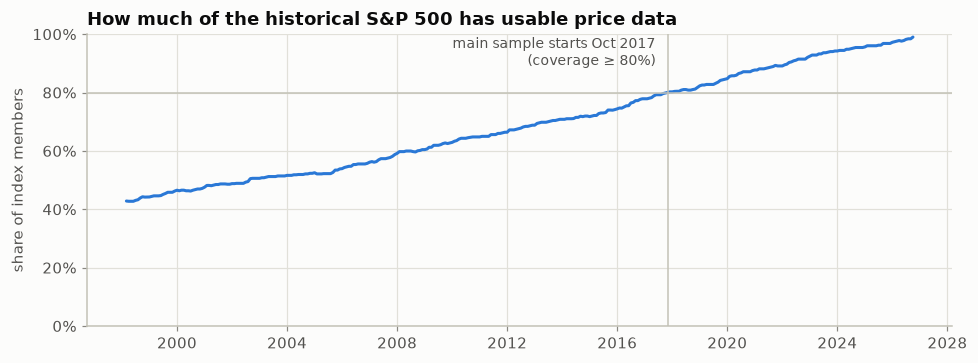

,index members,with usable prices,coverage
2005,496,261,53%
2006,497,275,55%
2007,497,285,57%
2008,497,298,60%
2009,499,309,62%
2010,498,321,64%
2011,497,326,66%
2012,497,338,68%
2013,497,349,70%
2014,498,356,71%


In [2]:
cov = monthly["coverage_at_formation"].dropna()
plots.coverage_chart(cov, cfg.min_coverage, OOS.start)
plt.show()
yearly = monthly[["n_members_at_formation", "n_eligible_at_formation", "coverage_at_formation"]]
yearly = yearly.loc[IS.start :].groupby(lambda d: d.year).mean()
yearly.columns = ["index members", "with usable prices", "coverage"]
yearly.style.format(
    {"index members": "{:.0f}", "with usable prices": "{:.0f}", "coverage": "{:.0%}"}
)

## 2. Method

At every month end:

1. **Universe:** that month's S&P 500 members with usable prices.
2. **Groups**, three ways:
   - **Broad sectors**: Yahoo's 11 sectors.
   - **Industries**: Yahoo's ~145 industries; only groups with ≥5 members count.
   - **Co-movement clusters**: stocks whose daily returns (after removing the market's move) were most
     correlated over the past year, re-formed every month from past data only (Ward linkage on correlation
     distance, ~12 names per cluster, ≥5 to count). This is the definition that can find a theme like
     "memory" on its own. Yahoo's labels are today's, applied to the past; the clusters have no such
     lookahead.
3. **Hot and cold groups:** groups ranked by their equal-weight return over the lookback (1, 3, 6 or 12 months).
   The top 20% are *hot*, the bottom 20% *cold*.
4. **Laggards and leaders:** the bottom and top third of each group by the same trailing return.
5. **Holding:** each month's basket is held for 1, 3 or 6 months; overlapping baskets are averaged
   (Jegadeesh–Titman), equal-weighted, with 10 bp one-way costs on every trade.

| Basket | What it tells you |
|---|---|
| **Hot-sector laggards** (the idea) | the hypothesis |
| Hot-sector leaders | would buying the strongest names in hot sectors be better? |
| Whole hot sector | is the edge just "be in the hot sector"? |
| Cold-sector laggards, laggards in every sector, laggards in the whole index | do laggards bounce anywhere, hot sector or not? |
| Equal-weight S&P 500, SPY | benchmarks |

The question is answered by **spreads**: the monthly return of one basket minus another.

| Spread | Asks |
|---|---|
| hot sector vs market | does sector momentum work here at all? |
| laggards vs rest of hot sector | inside a hot sector, are laggards better than the sector as a whole? |
| hot laggards vs hot leaders | inside a hot sector, laggards or leaders? |
| hot laggards vs laggards anywhere | does being in a *hot* sector help a laggard? |
| hot laggards vs market | the bottom line: does the idea beat just owning the index? |

t-statistics are Newey–West with lag = holding period. |t| ≳ 2 is the usual bar for "probably not luck",
and with 36 grid cells × 5 spreads, a few cells will clear it by chance alone.

## 3. Out-of-sample: the whole grid at once

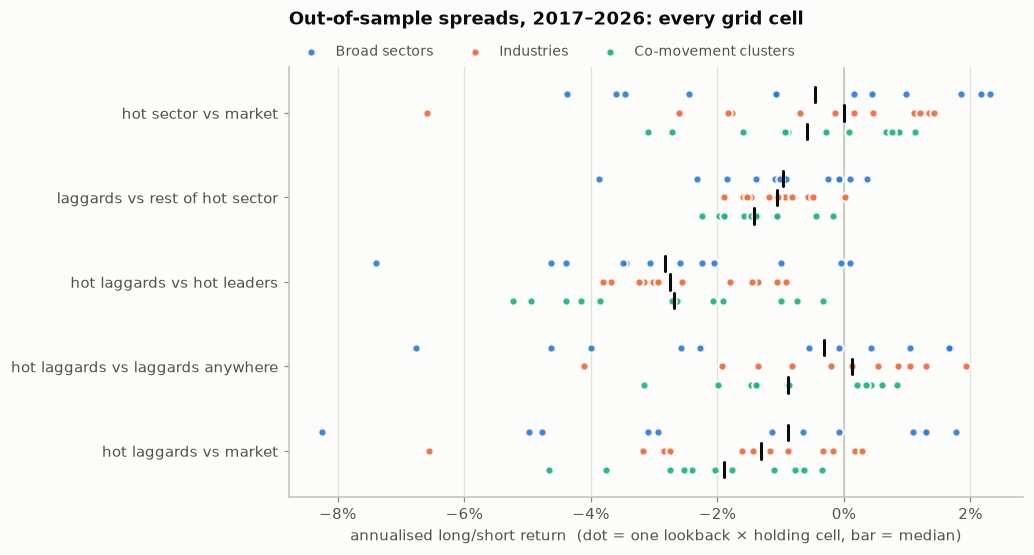

,median_ann,share_positive,cells_t_above_2,cells_t_below_minus_2
spread,,,,
hot sector vs market,-0.2%,47%,0,0
laggards vs rest of hot sector,-1.1%,8%,0,2
hot laggards vs hot leaders,-2.7%,3%,0,2
hot laggards vs laggards anywhere,-0.1%,47%,0,0
hot laggards vs market,-1.3%,17%,0,6


In [3]:
spreads_oos = A.spread_table(returns, OOS)
spreads_is = A.spread_table(returns, IS)
plots.spread_strips(
    spreads_oos, f"Out-of-sample spreads, {OOS.start:%Y}–{OOS.end:%Y}: every grid cell"
)
plt.show()
summary = spreads_oos.groupby("spread", sort=False).agg(
    median_ann=("ann", "median"),
    share_positive=("ann", lambda s: (s > 0).mean()),
    cells_t_above_2=("t", lambda s: int((s > 2).sum())),
    cells_t_below_minus_2=("t", lambda s: int((s < -2).sum())),
)
summary.style.format({"median_ann": "{:+.1%}", "share_positive": "{:.0%}"})

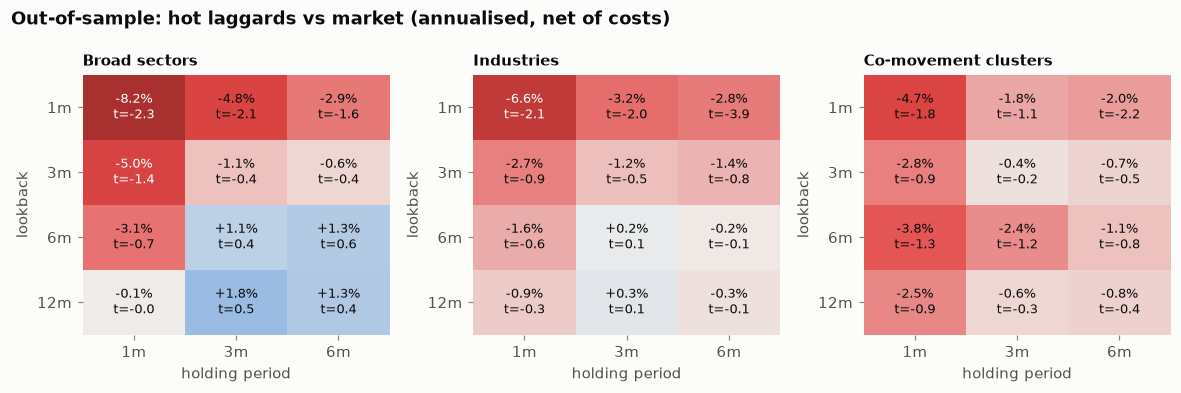

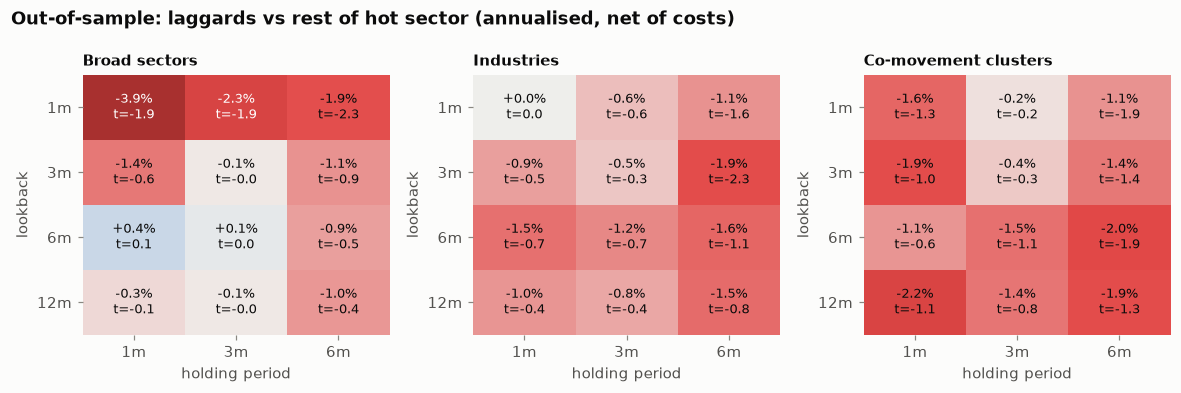

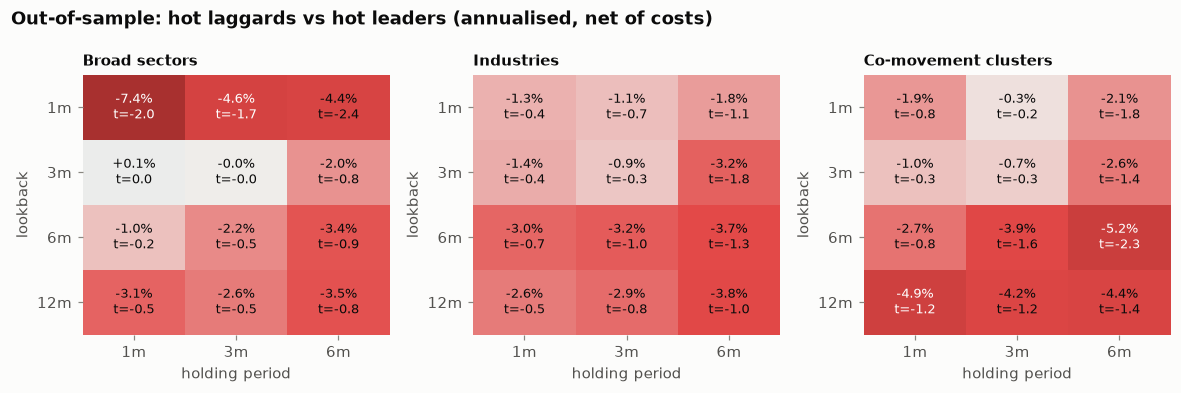

In [4]:
for spread in [
    "hot laggards vs market",
    "laggards vs rest of hot sector",
    "hot laggards vs hot leaders",
]:
    plots.spread_heatmaps(
        spreads_oos, spread, f"Out-of-sample: {spread} (annualised, net of costs)"
    )
    plt.show()

## 4. Does in-sample predict out-of-sample?

Each dot is one grid cell. If the idea had a stable edge, cells that worked in the early years would
also work later, and the dots would sit along the diagonal in the top-right quadrant.

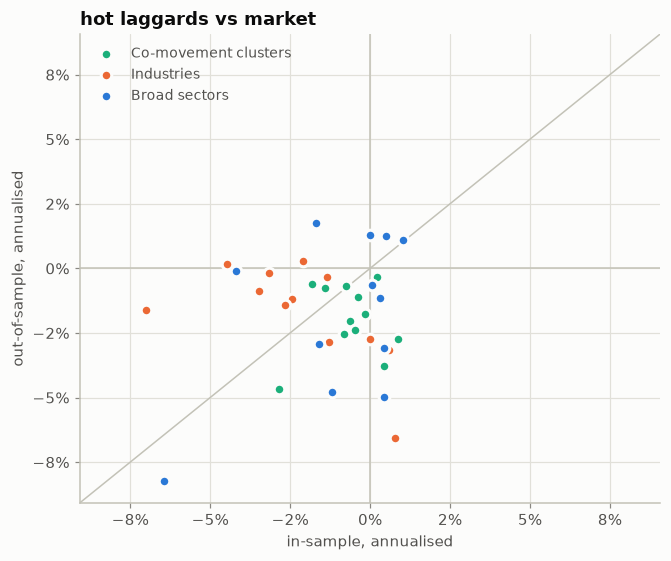

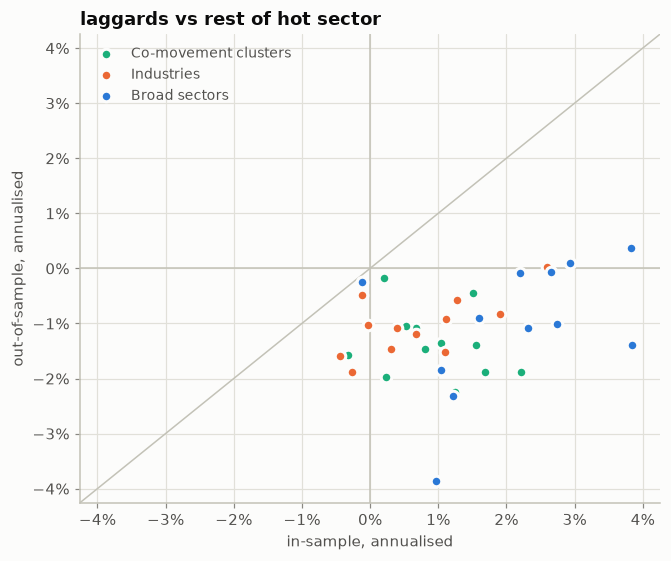

In [5]:
for spread in ["hot laggards vs market", "laggards vs rest of hot sector"]:
    plots.is_vs_oos(spreads_is, spreads_oos, spread, spread)
    plt.show()

## 5. The best in-sample version, tested out-of-sample

To avoid cherry-picking, the parameters are chosen **only on the in-sample years**: the grid cell with the
highest in-sample t-stat for *hot laggards vs market*. Then that cell is run on the out-of-sample years
it has never seen.

In-sample pick: **Broad sectors**, 6-month lookback, 3-month hold (in-sample: +1.0%/yr vs market, t = 0.5).

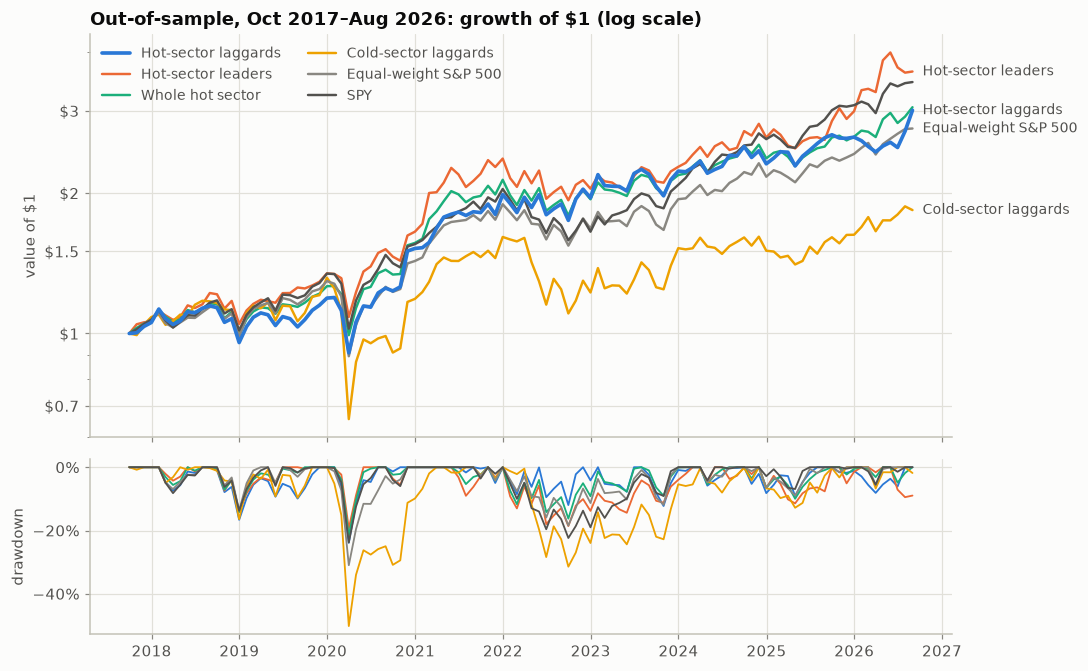

,cagr,vol,sharpe,max_dd,excess_ann,excess_t,months
"Laggards, every sector",+10.8%,20.9%,0.48,-34%,-0.6%,-0.41,107
Whole cold sector,+9.1%,23.7%,0.39,-47%,-1.4%,-0.64,107
Cold-sector laggards,+7.1%,27.8%,0.30,-50%,-2.2%,-0.67,107
Whole hot sector,+13.3%,17.5%,0.66,-22%,+1.0%,0.52,107
Hot-sector laggards,+13.1%,19.1%,0.61,-24%,+1.1%,0.39,107
Hot-sector leaders,+15.6%,19.4%,0.71,-19%,+3.3%,0.97,107
Equal-weight S&P 500,+12.0%,18.3%,0.58,-31%,+0.0%,nan,107
"Laggards, whole index",+10.1%,22.0%,0.44,-36%,-1.0%,-0.64,107
SPY,+14.9%,16.9%,0.76,-24%,+2.3%,1.13,107


In [6]:
best = A.choose_in_sample(spreads_is, "hot laggards vs market")
cell = {
    "scheme": best["scheme"],
    "lookback": int(best["lookback"]),
    "holding": int(best["holding"]),
}
display(
    Markdown(
        f"In-sample pick: **{plots.SCHEME_NAMES[cell['scheme']]}**, "
        f"{cell['lookback']}-month lookback, {cell['holding']}-month hold "
        f"(in-sample: {best['ann']:+.1%}/yr vs market, t = {best['t']:.1f})."
    )
)
keys = ["hot_laggards", "hot_leaders", "hot_all", "cold_laggards", "universe"]
curves = {k: OOS(A.series(returns, **cell, basket=k)) for k in keys}
curves["spy"] = OOS(monthly["spy"]).reindex(curves["universe"].index)
plots.growth_chart(
    curves, f"Out-of-sample, {OOS.start:%b %Y}–{OOS.end:%b %Y}: growth of $1 (log scale)"
)
plt.show()
grid_oos = A.grid_table(returns, monthly, OOS)
sel = grid_oos[
    (grid_oos.scheme == cell["scheme"])
    & (grid_oos.lookback == cell["lookback"])
    & (grid_oos.holding == cell["holding"])
].set_index("basket")
spy = A.summarize(curves["spy"], monthly["RF"], curves["universe"], lags=cell["holding"])
table = pd.concat(
    [sel.drop(columns=["scheme", "lookback", "holding"]), pd.DataFrame([spy], index=["spy"])]
)
table.index = [plots.BASKET_NAMES[k] for k in table.index]
table.style.format(
    {
        "cagr": "{:+.1%}",
        "vol": "{:.1%}",
        "sharpe": "{:.2f}",
        "max_dd": "{:.0%}",
        "excess_ann": "{:+.1%}",
        "excess_t": "{:.2f}",
        "months": "{:.0f}",
    }
)

`excess_ann` and `excess_t` are measured against the equal-weight S&P 500, the fair benchmark for
equal-weighted baskets. SPY is cap-weighted and was carried by mega-caps over much of this period.

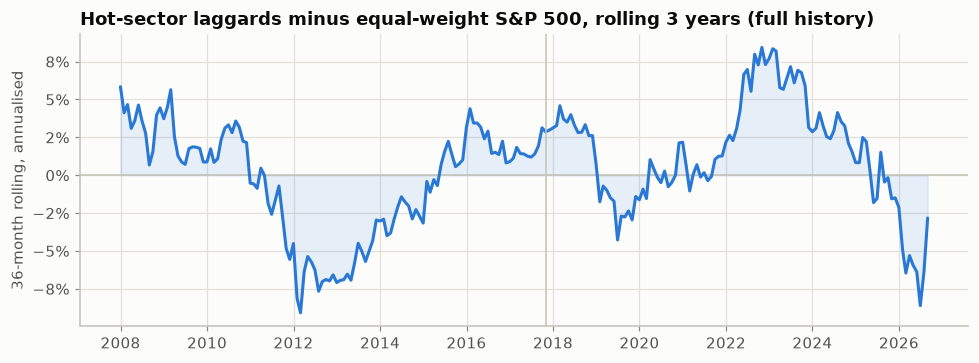

In [7]:
spread_series = A.series(returns, **cell, basket="hot_laggards") - A.series(
    returns, **cell, basket="universe"
)
plots.rolling_chart(
    spread_series.loc[IS.start :],
    36,
    "Hot-sector laggards minus equal-weight S&P 500, rolling 3 years (full history)",
)
plt.axvline(OOS.start, color=plots.AXIS, linewidth=1)
plt.show()

## 6. Pick by pick: do laggards catch up with their own sector?

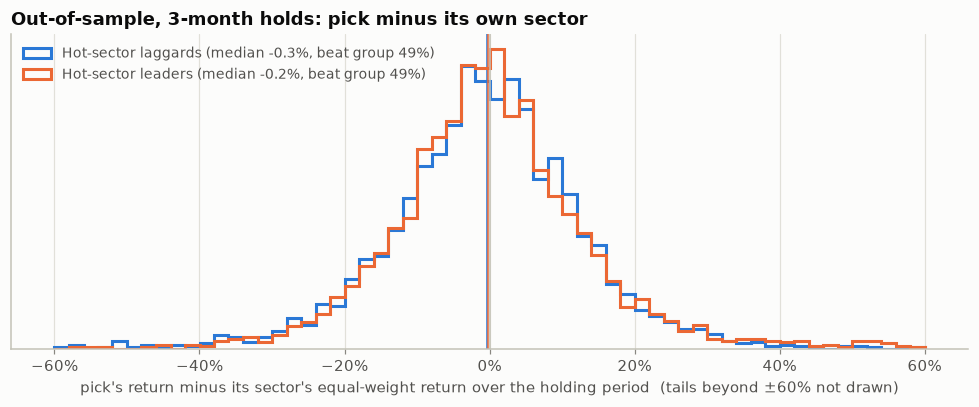

In [8]:
o = outcomes[
    (outcomes.scheme == cell["scheme"])
    & (outcomes.lookback == cell["lookback"])
    & (outcomes.holding == cell["holding"])
]
o = o[(o.date >= OOS.start - pd.offsets.MonthEnd(1)) & (o.date < OOS.end)]
plots.outcome_histogram(
    o, f"Out-of-sample, {cell['holding']}-month holds: pick minus its own sector"
)
plt.show()
hits = A.hit_rates(outcomes, OOS)
hits = hits.pivot_table(
    index=["scheme", "basket"],
    columns="holding",
    values=["beat_group", "median_vs_group"],
    aggfunc="mean",
)
hits.style.format("{:.1%}")

The hit-rate table averages over all lookbacks. `beat_group` is the share of picks that beat their own
sector's equal-weight return over the holding period, and `median_vs_group` is the typical pick's gap to
its sector.

## 7. Is it something already known?

The factor regression asks whether the basket's returns are explained by well-known return drivers:
the market, size (SMB), value (HML), profitability (RMW), investment (CMA), momentum (Mom), and
short-term reversal (ST_Rev, last month's losers bouncing back), with factor data from the
Ken French Data Library. Positive `ST_Rev` and negative `Mom` loadings would mean the "laggard
catch-up" is mostly the known reversal effect. The alpha is what's left over (annualised).

In [9]:
rows = {}
for k in ["hot_laggards", "hot_leaders", "hot_all", "universe"]:
    reg = A.factor_table(OOS(A.series(returns, **cell, basket=k)), monthly, lags=cell["holding"])
    rows[plots.BASKET_NAMES[k]] = pd.concat(
        [reg["coef"], pd.Series({"t(alpha)": reg.loc["alpha", "t"], "R²": reg.attrs["r2"]})]
    )
pd.DataFrame(rows).T.style.format("{:.2f}").format({"alpha": "{:+.1%}"})

,alpha,Mkt-RF,SMB,HML,RMW,CMA,Mom,ST_Rev,t(alpha),R²
Hot-sector laggards,+2.1%,0.868789,0.044002,0.044698,-0.054565,0.439729,-0.220254,0.252303,0.762897,0.786646
Hot-sector leaders,+2.7%,0.896596,0.123878,0.334888,-0.140705,-0.245408,0.291982,0.098805,0.726195,0.659897
Whole hot sector,+1.4%,0.856689,0.084857,0.192346,-0.051983,0.092075,0.035988,0.189616,0.648923,0.783439
Equal-weight S&P 500,-0.1%,0.909966,0.183690,0.185235,0.072317,0.133158,-0.013092,0.241586,-0.094399,0.894228


## 8. Trading costs

In [10]:
cs = A.cost_sensitivity(returns, monthly, OOS, cell, cfg.cost_grid)
cs["basket"] = cs["basket"].map(plots.BASKET_NAMES)
turn = A.ann_turnover(returns, OOS)
turn = turn[
    (turn.scheme == cell["scheme"])
    & (turn.lookback == cell["lookback"])
    & (turn.holding == cell["holding"])
].set_index("basket")["turnover_per_year"]
display(
    Markdown(
        "One-way turnover per year: "
        + ", ".join(
            f"{plots.BASKET_NAMES[k]} {v:.0%}" for k, v in turn.items() if k in plots.BASKET_COLORS
        )
    )
)
cs.pivot(
    index="basket", columns="cost_bps", values=["cagr", "excess_ann", "excess_t"]
).style.format("{:+.2f}").format("{:+.1%}", subset=pd.IndexSlice[:, ["cagr", "excess_ann"]])

One-way turnover per year: Cold-sector laggards 321%, Whole hot sector 271%, Hot-sector laggards 337%, Hot-sector leaders 327%, Equal-weight S&P 500 36%

## 9. Case study: Micron's cluster

This is the motivating example. Every month the co-movement clusters are re-formed, and Micron (MU) lands
with whichever stocks traded most like it over the past year. Over 2023–2026 that group drifts from
storage and PC hardware, to semiconductors, to a broad AI-infrastructure basket.

The table scores the rule (3-month lookback, 3-month hold) on **every** month since 2023 in which MU's
cluster was hot. For each month it shows the average next-3-month return of the laggards bought, the
leaders skipped, and the whole cluster.

In [11]:
L_CASE, H_CASE = 3, 3
cl = groups[groups.scheme == "cluster"]
pk = picks[(picks.scheme == "cluster") & (picks.lookback == L_CASE)]
mu_group = cl[cl.ticker == "MU"].set_index("date")["group"]
oc = outcomes[
    (outcomes.scheme == "cluster") & (outcomes.lookback == L_CASE) & (outcomes.holding == H_CASE)
]
rows = []
for d, g in mu_group.loc["2023":].items():
    in_cluster = oc[(oc.date == d) & (oc.group == g)]
    if not ((pk.date == d) & (pk.basket == "hot_all") & (pk.group == g)).any() or in_cluster.empty:
        continue
    rows.append(
        {
            "formed": d.strftime("%Y-%m"),
            "size": int(((cl.date == d) & (cl.group == g)).sum()),
            "laggards": in_cluster.loc[in_cluster.basket == "hot_laggards", "ret"].mean(),
            "leaders": in_cluster.loc[in_cluster.basket == "hot_leaders", "ret"].mean(),
            "whole cluster": in_cluster["group_ret"].iloc[0],
        }
    )
episodes = pd.DataFrame(rows).set_index("formed")
episodes["laggards − leaders"] = episodes["laggards"] - episodes["leaders"]
avg = episodes.drop(columns="size").mean().rename("average")
display(
    pd.concat([episodes, avg.to_frame().T]).style.format(
        {
            "size": "{:.0f}",
            "laggards": "{:+.1%}",
            "leaders": "{:+.1%}",
            "whole cluster": "{:+.1%}",
            "laggards − leaders": "{:+.1%}",
        },
        na_rep="",
    )
)
display(
    Markdown(
        f"Laggards beat leaders in **{(episodes['laggards − leaders'] > 0).sum()} of "
        f"{len(episodes)}** hot months for MU's cluster."
    )
)

,size,laggards,leaders,whole cluster,laggards − leaders
2023-01,6,-1.6%,-18.7%,-8.4%,+17.1%
2023-03,17,+13.2%,+20.4%,+13.8%,-7.2%
2023-04,17,+18.7%,+31.0%,+26.7%,-12.3%
2023-05,14,+18.9%,+12.8%,+12.5%,+6.1%
2023-07,12,+3.7%,-8.3%,-6.2%,+12.0%
2023-09,9,+9.9%,+10.3%,+11.3%,-0.4%
2024-04,12,+9.1%,+0.3%,+7.7%,+8.9%
2024-06,19,-9.3%,-2.8%,-8.8%,-6.6%
2025-06,10,+31.7%,+60.6%,+38.5%,-28.9%
2025-07,13,-6.7%,+51.4%,+28.0%,-58.1%


Laggards beat leaders in **6 of 20** hot months for MU's cluster.

One episode up close. To avoid choosing it for its outcome, it is picked by rule: the **tightest**
(fewest-member) hot MU cluster since 2025 with three months of after-data, the closest thing to a pure
"memory" group.

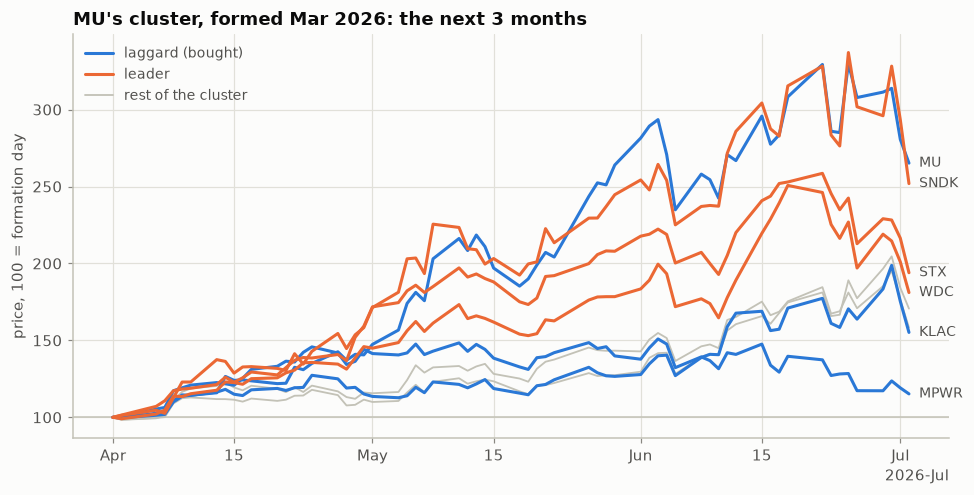

,industry (Yahoo),trailing 3m,next 3m,role
MU,Semiconductors,+18.4%,+165.2%,laggard
MPWR,Semiconductors,+20.9%,+15.2%,laggard
KLAC,Semiconductor Equipment & Materials,+21.3%,+55.2%,laggard
LRCX,Semiconductor Equipment & Materials,+25.0%,+58.4%,middle
AMAT,Semiconductor Equipment & Materials,+33.2%,+70.7%,middle
STX,Computer Hardware,+42.5%,+94.0%,leader
WDC,Computer Hardware,+57.1%,+81.1%,leader
SNDK,Computer Hardware,+167.6%,+151.9%,leader


In [12]:
recent = episodes.loc["2025-01":]
d = pd.Timestamp(recent["size"].idxmin()) + pd.offsets.MonthEnd(0)
d = mu_group.index[mu_group.index.to_period("M") == d.to_period("M")][0]
g = mu_group[d]
members = cl[(cl.date == d) & (cl.group == g)]["ticker"].tolist()
on_d = pk[(pk.date == d) & (pk.group == g)]
lag = set(on_d.loc[on_d.basket == "hot_laggards", "ticker"])
lead = set(on_d.loc[on_d.basket == "hot_leaders", "ticker"])
roles = pd.Series(
    {t: "laggard" if t in lag else "leader" if t in lead else "middle" for t in members}
)

close = pd.read_parquet(config.CACHE / "prices.parquet")
close.index = pd.DatetimeIndex(close.index)
labels = pd.read_csv(config.CACHE / "classification.csv").set_index("ticker")
start = close.index[close.index > d][0]
window = close.loc[start:, members].iloc[: 21 * H_CASE + 1]
paths = 100 * window / window.iloc[0]
back = close.loc[:d, members]
trailing = back.iloc[-1] / back.loc[: d - pd.DateOffset(months=L_CASE)].iloc[-1] - 1

plots.case_study_chart(paths, roles, f"MU's cluster, formed {d:%b %Y}: the next {H_CASE} months")
plt.show()
tbl = pd.DataFrame(
    {
        "industry (Yahoo)": labels.reindex(members)["industry"],
        f"trailing {L_CASE}m": trailing,
        f"next {H_CASE}m": paths.iloc[-1] / 100 - 1,
        "role": roles,
    }
).sort_values(f"trailing {L_CASE}m")
tbl.style.format({f"trailing {L_CASE}m": "{:+.1%}", f"next {H_CASE}m": "{:+.1%}"})

One episode is a story, not evidence: it shows the mechanics, and sections 3–8 are the test.

## 10. Caveats that remain

- **Survivorship.** Even after 2018, a few percent of each month's index members are missing from Yahoo,
  mostly companies later acquired or delisted. Stocks that stop trading mid-hold are treated as cash at
  their last quote, with no delisting return.
- **Labels from today.** Yahoo's sector and industry labels are current ones, applied to the past.
  The co-movement clusters avoid this.
- **Large caps only.** The S&P 500 is the most efficiently priced corner of the market. The idea could
  behave differently in mid and small caps, but free point-in-time data for those isn't available.
- **Ticker reuse.** Spells where Yahoo's history starts after the spell began are dropped. A rename that
  Yahoo back-fills (old AT&T versus SBC under "T") can still mix two companies, mostly before the main sample.
- **Short main sample.** About 8½ years out-of-sample is enough to see a large effect, not a small one.